In [1]:
## Predict salary using years of experience

In [33]:
import pandas as pd
!pip install scikit-learn
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score


[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: C:\Users\RAJESH\AppData\Local\Programs\Python\Python312\python.exe -m pip install --upgrade pip


In [34]:
df = pd.read_csv("../Files/salary.csv")
df.head()

,YearsExperience,Salary
0,1.1,39343.0
1,1.3,46205.0
2,1.5,37731.0
3,2.0,43525.0
4,2.2,39891.0


In [35]:
x = df[["YearsExperience"]] ## X axis feature double [] convention hien
y = df["Salary"] ## y axis are label

In [36]:
## Split data
x_train,x_test, y_train, y_test = train_test_split(x,y,test_size=0.20,random_state=101)

In [37]:
## Fit smple regression to training data
model = LinearRegression()
model.fit(x_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[9440.46]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['YearsExperience']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.604e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [38]:
## make prediction
y_pred = model.predict(x_test)
print(f"Predicted values on test set : {y_pred}")

Predicted values on test set : [ 90235.22172621 108172.10301013  56249.55192509  81738.80427593
  40200.76340789 116668.52046041]


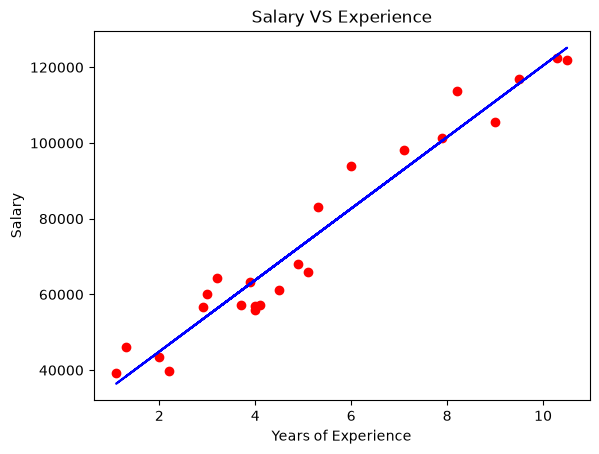

In [39]:
## Training set result
plt.scatter(x_train,y_train, color='red')
plt.plot(x_train,model.predict(x_train), color='blue')
plt.title("Salary VS Experience")
plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.show()

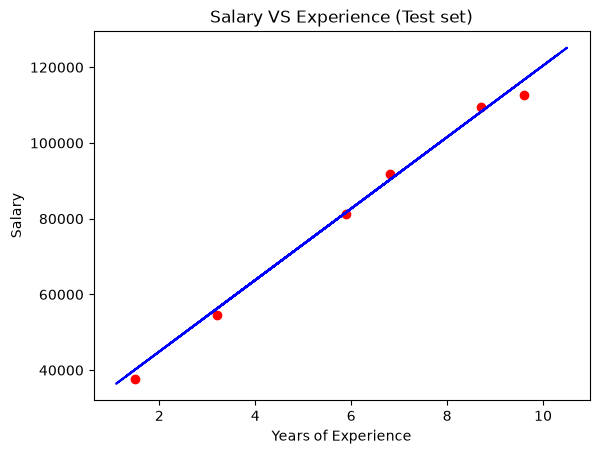

In [40]:
## Test set result
plt.scatter(x_test,y_test,color="red")
plt.plot(x_train,model.predict(x_train) , color="blue")
plt.title("Salary VS Experience (Test set)")
plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.show()

In [41]:
## Make new prediction

new_X_values_df = pd.DataFrame({"YearsExperience":[1,3,6,8,12,15,20,25]})

In [42]:
new_y_pred = model.predict(new_X_values_df)
print("\n Predictions for new experience values : \n" , new_y_pred)


 Predictions for new experience values : 
 [ 35480.53149107  54361.45915836  82682.85065929 101563.77832658
 139325.63366116 167647.0251621  214849.34433032 262051.66349855]


In [44]:
## model evaluation
mae = mean_absolute_error(y_test,y_pred)
mse = mean_squared_error(y_test,y_pred)
r2 = r2_score(y_test, y_pred)

In [46]:
print(f"MAE : {mae} \nMSE : {mse} \nr2-score : {r2}")

MAE : 1907.5525554956257 
MSE : 4934969.878489006 
r2-score : 0.993422386435995


### Predict house sale price using Gr Living area

In [81]:
df = pd.read_csv("../Files/housing.csv")

df.head()

,Id,LotArea,OverallQual,YearBuilt,TotalBsmtSF,GrLivArea,FullBath,BedroomAbvGr,KitchenQual,TotRmsAbvGrd,GarageArea,SalePrice
0,1,8450,7,2003,856,1710,2,3,Gd,8,548,208500
1,2,9600,6,1976,1262,1262,2,3,TA,6,460,181500
2,3,11250,7,2001,920,1786,2,3,Gd,6,608,223500
3,4,9550,7,1915,756,1717,1,3,Gd,7,642,140000
4,5,14260,8,2000,1145,2198,2,4,Gd,9,836,250000


In [90]:
x = df[["GrLivArea","LotArea","YearBuilt"]]
y = df["SalePrice"]

In [91]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.20,random_state=101)
model = LinearRegression()


In [92]:
model.fit(x_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[ 94.01, 0.88,1074.95]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](3,)","['GrLivArea','LotArea','YearBuilt']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-2.09e+06
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)


In [93]:
y_pred = model.predict(x_test)
print(f"Predicted values on test set : {y_pred}")

Predicted values on test set : [259432.27983485 145337.22266397 141093.1850105  326373.55650299
 270617.84890131  80605.05722371 208741.51281139 181315.90138851
 157515.93273567 139222.64880555 122615.61804175 150060.31856483
 129813.54464875 163875.95969416 181357.62845671 184949.02607846
 193396.29844064 117754.34937629 165136.69153886 245214.23131284
 121816.71673986  48930.51440592 206825.13210041 175176.39459843
 254034.92516312 133164.04540222  89744.38079157 171697.91221193
 225318.71793895 146541.61550866 231724.74894118 156455.50262762
 216249.70584794 231764.63492084  38070.6348671  110669.24872208
 300236.80039627 249221.41583967 139591.57890486 123859.45572901
 279182.73340658 220099.07552809 239170.1933058  207203.15895246
 173022.86897283 146408.97299407 321118.04417808 198400.2600886
 122813.29664098 121864.9912075  181613.01833755 252256.54942288
  59963.97880435 218417.64707874 226145.24665678 143586.17788211
 202587.07029733 221252.30423711 158806.17212683 216525.2529

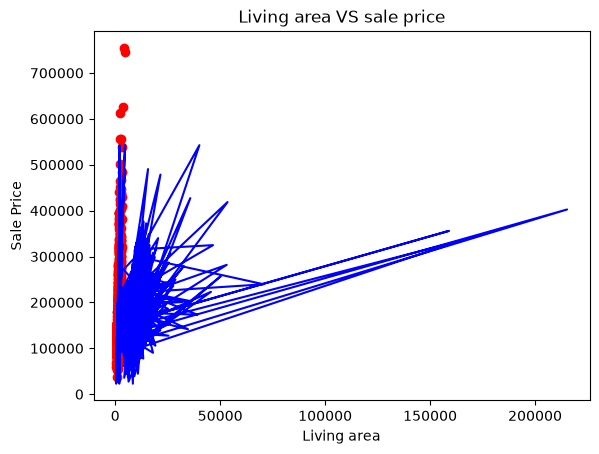

In [97]:
## Training set result
plt.scatter(x_train["GrLivArea"],y_train, color='red')
plt.plot(x_train,model.predict(x_train), color='blue')
plt.title("Living area VS sale price")
plt.xlabel("Living area")
plt.ylabel("Sale Price")
plt.show()

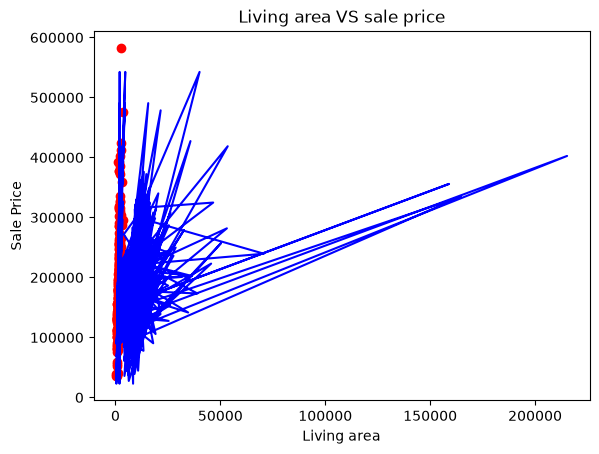

In [100]:
## Test set result
plt.scatter(x_test["GrLivArea"],y_test,color="red")
plt.plot(x_train,model.predict(x_train) , color="blue")
plt.title("Living area VS sale price")
plt.xlabel("Living area")
plt.ylabel("Sale Price")
plt.show()

In [99]:
## model evaluation
mae = mean_absolute_error(y_test,y_pred)
mse = mean_squared_error(y_test,y_pred)
r2 = r2_score(y_test, y_pred)

In [96]:
print(f"MAE : {mae} \nMSE : {mse} \nr2-score : {r2}")

MAE : 31236.105128290503 
MSE : 2687348370.1875987 
r2-score : 0.5485783751173512
